# T1 - Compte rendu du TP1

<img src="https://www.universite-paris-saclay.fr/sites/default/files/media/2019-12/logo-ups.svg" alt="Logo Paris Saclay" width=200 height=200>
<strong>Encadrants :</strong><br> Omar Hammami </br> Nicolas GAC <br></br>
<strong>Auteurs :</strong><ul><li>ABOU JAOUDE Thomas</li><li>BERCY Victor</li><li>BOUCHY Gaëtan</li></ul>

## Introduction

Le noeud technologique choisi dans les paramètres de configuration du logiciel est CACTI est le suivant : 32 nm.

<strong>N.B. :</strong> Le dossier cacti65 contenant le logiciel CACTI (et notamment l'exécutable cacti) est supposé être placé dans le même dossier que ce notebook.

## Imports

In [1]:
import subprocess
from os import chdir
import re

from mpl_toolkits import mplot3d
import numpy as np
import matplotlib.pyplot as plt

chdir("./cacti65")

## Fonctions utiles 

In [2]:
def get_info():
    """
    Récupère les valeurs de temps d'accès, surface et énergie simulées via Cacti pour une configuration de cache
    """
    # Lancer la simulation
    info = subprocess.check_output(["wsl", "./cacti", "-infile", "cache.cfg"])
    # Récupérer la sortie du logiciel CACTI
    info = (info.decode("utf-8")).split("\n")
    
    # Extraire de cette sortie les informations pertinentes
    energy = 0
    for x in info:
        if "Access time" in x:
            ta = x.split(":")[-1].strip()
        elif "Activate Energy" in x:
            energy += float(x.split(":")[-1].strip())
        elif "Read Energy" in x:
            energy += float(x.split(":")[-1].strip())
        elif "Write Energy" in x:
            energy += float(x.split(":")[-1].strip())
        elif "Precharge Energy" in x:
            energy += float(x.split(":")[-1].strip())
        elif "Cache height x width" in x:
            cache_size = x.split(":")[-1].strip()

    return float(ta), cache_size, float(energy)


def write_cfg(s=65536, a=4, mode="normal", readWrite=1, read=0, write=0):
    """
    Modifie les valeurs de taille, d'associativité, de mode d'accès et de nombre de ports dans le fichier .cfg de Cacti
    """
    # Récupérer le contenu du fichier de configuration
    with open("cache.cfg", "r") as f:
        txt = f.readlines()
    f.close()
    
    # Réécrire les lignes qui nous intéressent
    with open("cache.cfg", "w") as f:
        for line in txt:
            if line[0]!="/":
                if "-size (bytes)" in line:
                    line = "-size (bytes) " + f"{s}\n"
                elif "-associativity" in line:
                    line = "-associativity " + f"{a}\n"
                elif "-access mode (normal, sequential, fast)" in line:
                    line = '-access mode (normal, sequential, fast) - "' + mode + '"\n'
                elif "-exclusive read port" in line:
                    line = "-exclusive read port " + f"{read}\n"
                elif "-exclusive write port" in line:
                    line = "-exclusive write port " + f"{write}\n"
                elif "-read-write port" in line:
                    line = "-read-write port " + f"{readWrite}\n"
            f.write(line)
    f.close()
    
    return None

def getTAMM(ta, taue, tm):
    """
    Calcule le temps d'accès mémoire moyen en fonction des temps d'accès des caches, de leur taux d'erreurs et du temps d'accès RAM
    N.B. 1 : si les caches L1d et L1i sont identiques, tout se passe comme si l'on avait un seul cache L1 (même temps d'accès), sinon on prend le plus grand temps d'accès des deux caches L1
    N.B. 2 : on suppose que les taux d'erreurs sont identiques quels que soient les caches
    """
    if len(ta) == 2:
        return ta[0] + taue * (ta[1] + taue * tm)
    elif len(ta) == 3:
        return ta[0] + taue * (ta[1] + taue * (ta[2] + taue * tm))
    else:
        raise ValueError(f"Le nombre de temps d'accès et/ou de taux d'erreurs indiqué est incorrect (jusqu'à L2 ou L3) : {len(ta)}.")

def getSurface(surfaces):
    """
    Calcule la surface totale du processeur simulé à partir d'un array numpy de toutes les surfaces de caches
    """
    return np.sum(surfaces)

def getConsumedEnergy(energies):
    """
    Calcule l'énergie totale consommée par le processeur simulé à partir d'un array numpy de toutes les énergies consommées par les caches
    """
    return np.sum(energies)

## Simulation d'architectures CACTI 

### 1. Analyse surface, temps d'accès, énergie 

#### Variables 

In [3]:
# Ensemble des tailles de caches possibles
sizes = [8192, 16384, 32768, 65536, 131072, 262144, 524288, 1048576, 2097152, 4194304]
# Ensemble des associativités possibles
associativity = [1, 2, 4, 8]

# Listes contenant le temps d'accès, l'énergie et la surface simulés pour chaque taille de cache
tpa, energie, surface = [], [], []  
# Listes contenant l'associativité et la taille du cache pour chaque simulation réalisée (pour rendu graphique)
asso, csize = [], []

#### Code 

In [4]:
for s in sizes:
    for a in associativity:
        print(f"Simulation cache de taille {s} bytes et d'associativité {a}...")
        write_cfg(s, a)
        t, cs, e = get_info()
        csize.append(s)
        asso.append(a)
        tpa.append(t)
        energie.append(e)
        x = re.findall("\d+\.\d+", cs)
        surface.append(float(x[0]) * float(x[1]))

Simulation cache de taille 8192 bytes et d'associativité 1...
Simulation cache de taille 8192 bytes et d'associativité 2...
Simulation cache de taille 8192 bytes et d'associativité 4...
Simulation cache de taille 8192 bytes et d'associativité 8...
Simulation cache de taille 16384 bytes et d'associativité 1...
Simulation cache de taille 16384 bytes et d'associativité 2...
Simulation cache de taille 16384 bytes et d'associativité 4...
Simulation cache de taille 16384 bytes et d'associativité 8...
Simulation cache de taille 32768 bytes et d'associativité 1...
Simulation cache de taille 32768 bytes et d'associativité 2...
Simulation cache de taille 32768 bytes et d'associativité 4...
Simulation cache de taille 32768 bytes et d'associativité 8...
Simulation cache de taille 65536 bytes et d'associativité 1...
Simulation cache de taille 65536 bytes et d'associativité 2...
Simulation cache de taille 65536 bytes et d'associativité 4...
Simulation cache de taille 65536 bytes et d'associativité 8

Text(0.5, 1.0, "Figure montrant le temps d'accès du cache en fonction de son associativité (taille en échelle)")

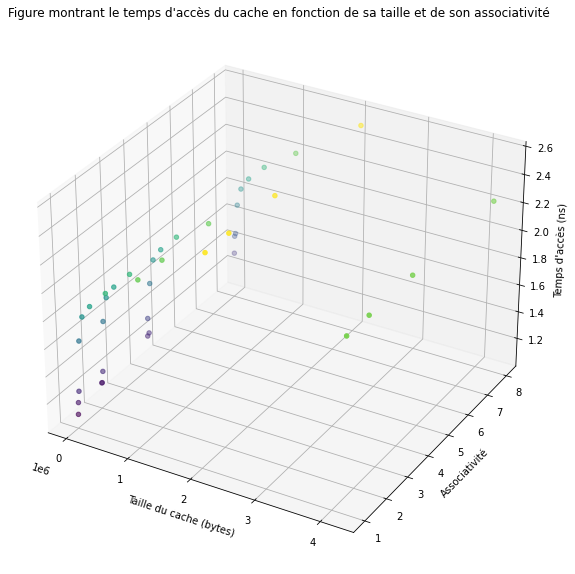

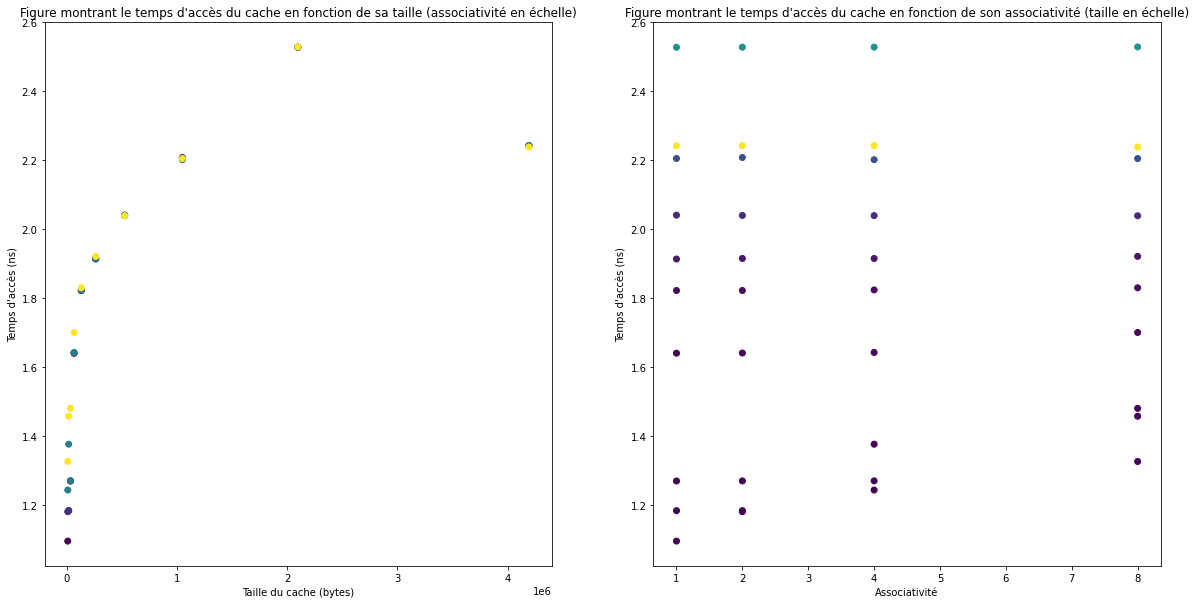

In [5]:
plt.figure(figsize=(10, 10))
ax = plt.axes(projection='3d')
ax.scatter3D(csize, asso, tpa, c = tpa, cmap = 'viridis')
ax.set_xlabel("Taille du cache (bytes)")
ax.set_ylabel("Associativité")
ax.set_zlabel("Temps d'accès (ns)")
ax.set_title("Figure montrant le temps d'accès du cache en fonction de sa taille et de son associativité")

plt.figure(figsize=(20, 10))
plt.subplot(121)
plt.scatter(csize, tpa, c = asso, cmap = 'viridis')
plt.xlabel("Taille du cache (bytes)")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant le temps d'accès du cache en fonction de sa taille (associativité en échelle)")
plt.subplot(122)
plt.scatter(asso, tpa, c = csize, cmap = 'viridis')
plt.xlabel("Associativité")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant le temps d'accès du cache en fonction de son associativité (taille en échelle)")

<strong>Interprétation :</strong>

On observe logiquement que, le temps d'accès au cache augmente avec sa taille, à l'exception près d'un cache de taille de 4MB ayant un temps d'accès proche de celui de taille 1 MB. De plus, on remarque que, quelle que soit la valeur de l'associativité du cache, le temps d'accès reste constant à taille de cache fixée sauf pour les petites tailles pour lesquelles le temps d'accès est fonction croissante de l'associativité.

Text(0.5, 1.0, 'Figure montrant la surface du cache en fonction de son associativité (taille en échelle)')

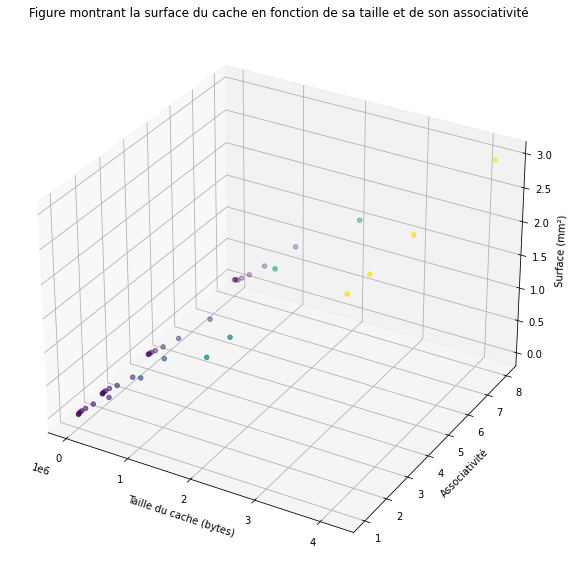

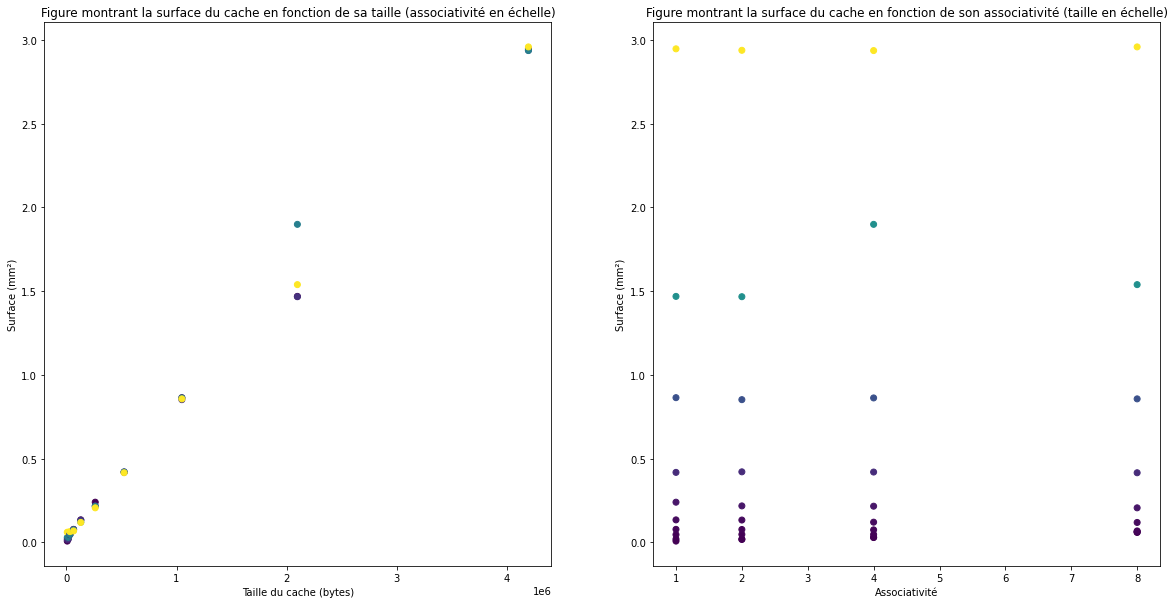

In [6]:
plt.figure(figsize=(10, 10))
ax = plt.axes(projection='3d')
ax.scatter3D(csize, asso, surface, c = surface, cmap = 'viridis')
ax.set_xlabel("Taille du cache (bytes)")
ax.set_ylabel("Associativité")
ax.set_zlabel("Surface (mm²)")
ax.set_title("Figure montrant la surface du cache en fonction de sa taille et de son associativité")

plt.figure(figsize=(20, 10))
plt.subplot(121)
plt.scatter(csize, surface, c = asso, cmap = 'viridis')
plt.xlabel("Taille du cache (bytes)")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant la surface du cache en fonction de sa taille (associativité en échelle)")
plt.subplot(122)
plt.scatter(asso, surface, c = csize, cmap = 'viridis')
plt.xlabel("Associativité")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant la surface du cache en fonction de son associativité (taille en échelle)")

<strong>Interprétation :</strong>

On observe logiquement une relation linéaire entre la taille en bytes du cache et la surface occupée par celui-ci. De plus, on remarque que quelle que soit la valeur de l'associativité du cache, la surface occupée reste constante (sauf cas particulier du cache de 2MB 4-associatif dont la surface augmente significativement par rapport au reste des caches).

Text(0.5, 1.0, "Figure montrant l'énergie consommée par le cache en fonction de son associativité (taille en échelle)")

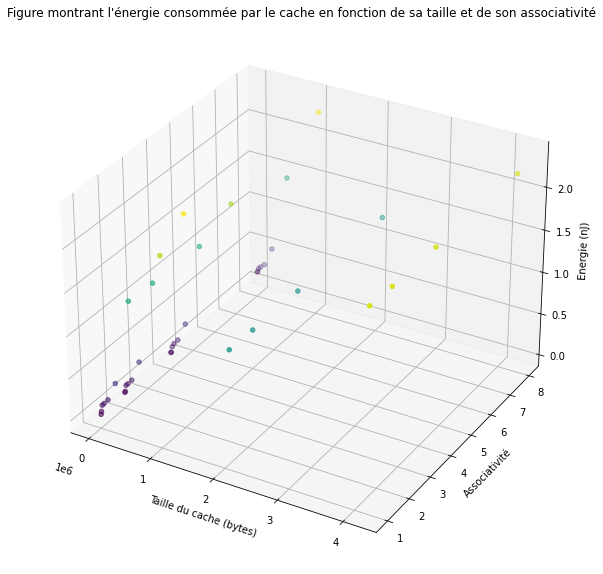

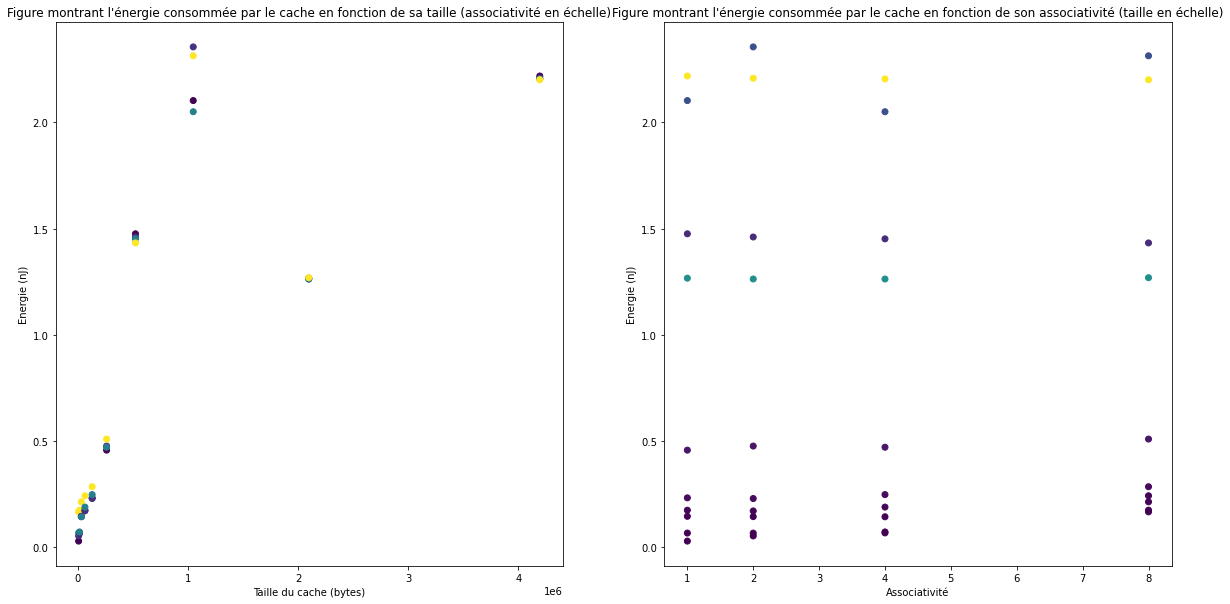

In [7]:
plt.figure(figsize=(10, 10))
ax = plt.axes(projection='3d')
ax.scatter3D(csize, asso, energie, c = energie, cmap = 'viridis')
ax.set_xlabel("Taille du cache (bytes)")
ax.set_ylabel("Associativité")
ax.set_zlabel("Energie (nJ)")
ax.set_title("Figure montrant l'énergie consommée par le cache en fonction de sa taille et de son associativité")

plt.figure(figsize=(20, 10))
plt.subplot(121)
plt.scatter(csize, energie, c = asso, cmap = 'viridis')
plt.xlabel("Taille du cache (bytes)")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'énergie consommée par le cache en fonction de sa taille (associativité en échelle)")
plt.subplot(122)
plt.scatter(asso, energie, c = csize, cmap = 'viridis')
plt.xlabel("Associativité")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'énergie consommée par le cache en fonction de son associativité (taille en échelle)")

<strong>Interprétation :</strong>

On observe que l'énergie consommée par le cache augmente fortement avec la taille de celui-ci jusqu'à ce que celle-ci atteignent 2 MB. De plus, on remarque que quelle que soit la valeur de l'associativité du cache, l'énergie consommée reste constante (sauf cas particulier du cache de taille 1 MB dont l'énergie varie significativement comparée aux autres).

### 2. Analyse impact nombre de ports lecture, écriture

In [8]:
# Listes contenant l'ensemble des configurations de ports que l'on souhaite simuler
ports = [(i,0,0) for i in range (1,11)] + [(1,i,0) for i in range (1,11)] + [(1,0,i) for i in range (1,11)] + [(0,i,i) for i in range (1,11)]
# Listes contenant le temps d'accès, l'énergie et la surface simulés pour chaque taille de cache
ta2, energie2, surface2 = [], [], []

In [9]:
for readWrite, read, write in ports:
    print(f"Simulation cache à {readWrite} port(s) lecture/écriture, {read} port(s) lecture et {write} port(s) écriture...")
    write_cfg(readWrite=readWrite, read=read, write=write)
    t, cs, e = get_info()
    ta2.append(t)
    energie2.append(e)
    x = re.findall("\d+\.\d+",cs)
    surface2.append(float(x[0]) * float(x[1]))

Simulation cache à 1 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 2 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 3 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 4 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 5 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 6 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 7 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 8 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 9 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 10 port(s) lecture/écriture, 0 port(s) lecture et 0 port(s) écriture...
Simulation cache à 1 port(s) lecture/écriture, 1 port(s) lecture et 0 port(s) écriture...
Simulatio

Text(0.5, 1.0, "Figure montrant l'influence du nombre de ports écriture sur le temps d'accès (1 seul autre port lecture/écriture)")

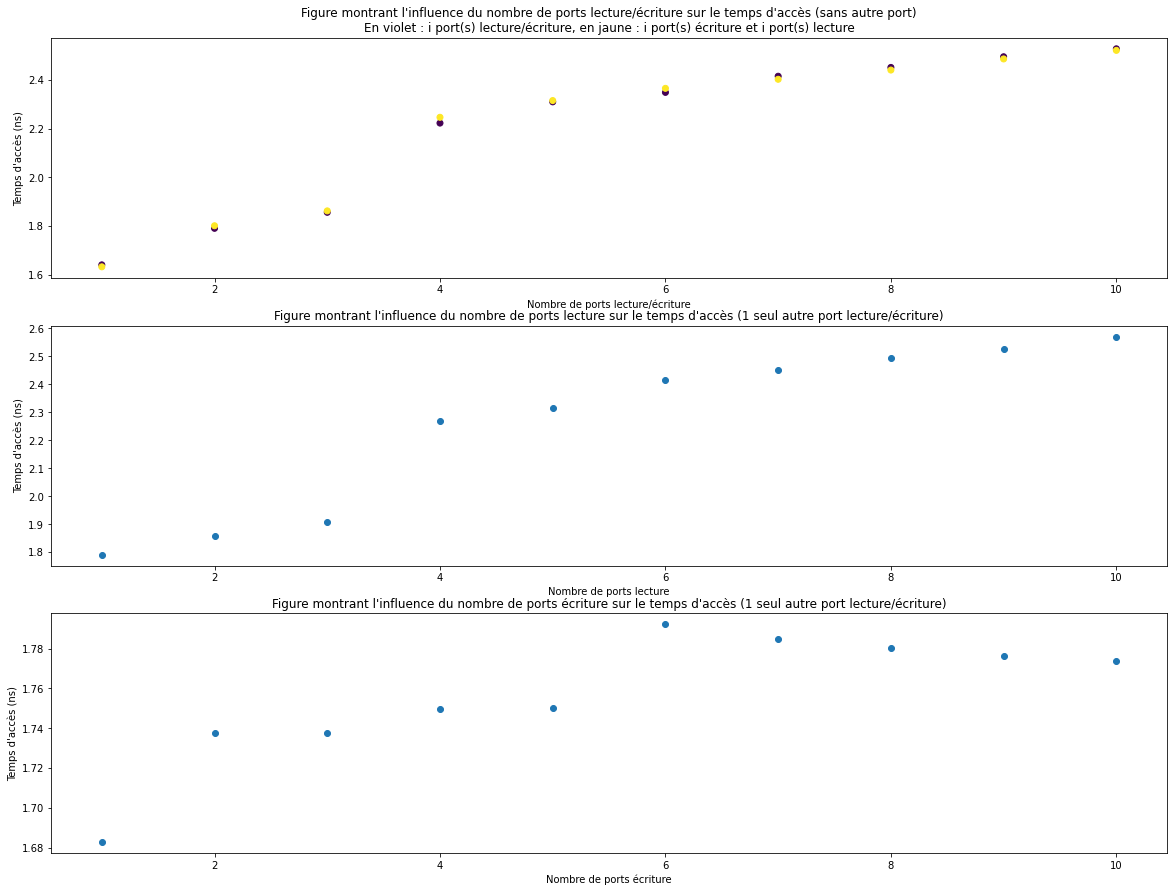

In [10]:
plt.figure(figsize=(20, 15))
plt.subplot(311)
plt.scatter([i for i in range (1,11)]*2, ta2[:10]+ta2[30:], c = [i//10 for i in range(20)], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture/écriture")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant l'influence du nombre de ports lecture/écriture sur le temps d'accès (sans autre port)\nEn violet : i port(s) lecture/écriture, en jaune : i port(s) écriture et i port(s) lecture")
plt.subplot(312)
plt.scatter([i for i in range (1,11)], ta2[10:20], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant l'influence du nombre de ports lecture sur le temps d'accès (1 seul autre port lecture/écriture)")
plt.subplot(313)
plt.scatter([i for i in range (1,11)], ta2[20:30], cmap = 'viridis')
plt.xlabel("Nombre de ports écriture")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant l'influence du nombre de ports écriture sur le temps d'accès (1 seul autre port lecture/écriture)")

<strong>Interprétation :</strong>

On remarque que la parallélisation de la lecture et de l'écriture n'a pas d'impact positif sur le temps d'accès au cache, au contraire elle rallonge étonnament celui-ci. La relation entre les nombres de ports et le temps d'accès semble linéaire (par morceaux pour l'écriture).

Text(0.5, 1.0, "Figure montrant l'influence du nombre de ports écriture sur la surface occupée (1 seul autre port lecture/écriture)")

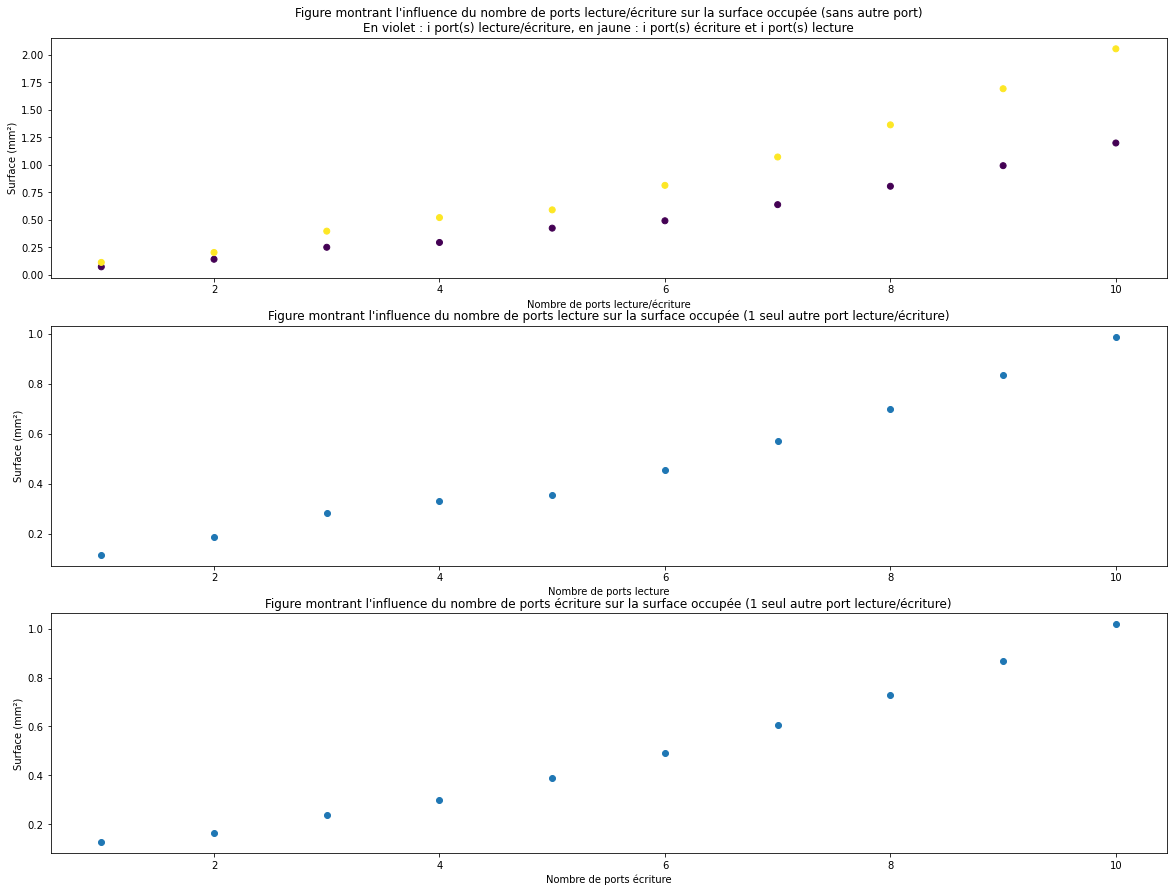

In [11]:
plt.figure(figsize=(20, 15))
plt.subplot(311)
plt.scatter([i for i in range (1,11)]*2, surface2[:10]+surface2[30:], c = [i//10 for i in range(20)], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture/écriture")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant l'influence du nombre de ports lecture/écriture sur la surface occupée (sans autre port)\nEn violet : i port(s) lecture/écriture, en jaune : i port(s) écriture et i port(s) lecture")
plt.subplot(312)
plt.scatter([i for i in range (1,11)], surface2[10:20], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant l'influence du nombre de ports lecture sur la surface occupée (1 seul autre port lecture/écriture)")
plt.subplot(313)
plt.scatter([i for i in range (1,11)], surface2[20:30], cmap = 'viridis')
plt.xlabel("Nombre de ports écriture")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant l'influence du nombre de ports écriture sur la surface occupée (1 seul autre port lecture/écriture)")

<strong>Interprétation :</strong>

On observe logiquement que plus le nombre de ports augmente, plus la surface occupée par le cache est grande. On remarque également qu'un port lecture/écriture occupe une plus petite surface qu'un port lecture et un port écriture, ainsi qu'un port écriture occupe une plus petite surface qu'un port écriture.

Text(0.5, 1.0, "Figure montrant l'influence du nombre de ports écriture sur l'énergie consommée (1 seul autre port lecture/écriture)")

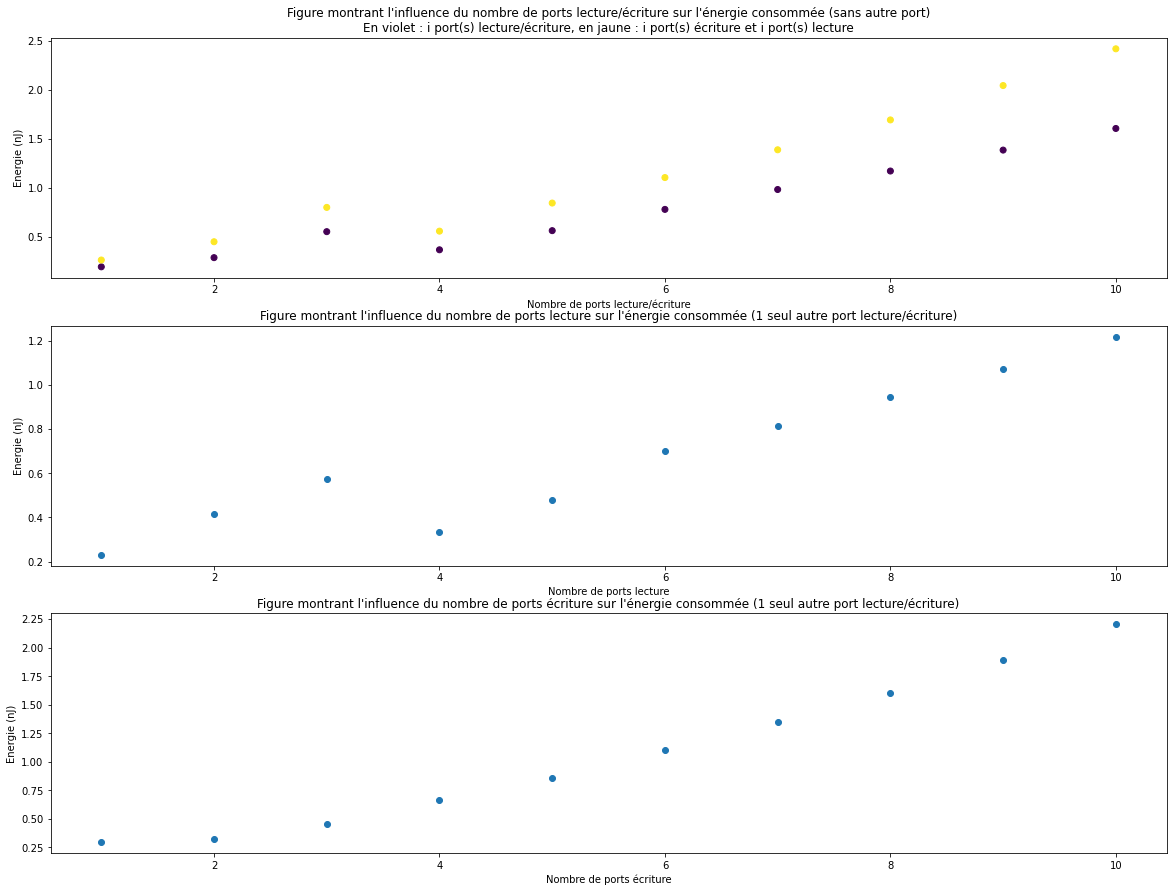

In [12]:
plt.figure(figsize=(20, 15))
plt.subplot(311)
plt.scatter([i for i in range (1,11)]*2, energie2[:10]+energie2[30:], c = [i//10 for i in range(20)], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture/écriture")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'influence du nombre de ports lecture/écriture sur l'énergie consommée (sans autre port)\nEn violet : i port(s) lecture/écriture, en jaune : i port(s) écriture et i port(s) lecture")
plt.subplot(312)
plt.scatter([i for i in range (1,11)], energie2[10:20], cmap = 'viridis')
plt.xlabel("Nombre de ports lecture")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'influence du nombre de ports lecture sur l'énergie consommée (1 seul autre port lecture/écriture)")
plt.subplot(313)
plt.scatter([i for i in range (1,11)], energie2[20:30], cmap = 'viridis')
plt.xlabel("Nombre de ports écriture")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'influence du nombre de ports écriture sur l'énergie consommée (1 seul autre port lecture/écriture)")

<strong>Interprétation :</strong>

On observe logiquement que plus le nombre de ports augmente, plus l'énergie consommée par le cache est grande. On remarque également qu'un port lecture/écriture nécessite moins d'énergie qu'un port lecture et un port écriture, ainsi qu'un port lecture demande plus d'énergie qu'un port écriture.

### 3. Analyse impact mode d'accès aux caches 

In [13]:
# Listes contenant les différents modes d'accès au cache possibles
modes = ["fast","normal", "sequential"]
# Listes contenant le temps d'accès, l'énergie et la surface simulés pour chaque taille de cache
ta3, energie3, surface3 = [], [], []

In [14]:
for a in associativity:
    for mode in modes:
        print(f"Simulation cache {a}-associatif accessible en mode {mode}...")
        write_cfg(a=a, mode=mode)
        t, cs, e = get_info()
        ta3.append(t)
        energie3.append(e)
        x = re.findall("\d+\.\d+",cs)
        surface3.append(float(x[0]) * float(x[1]))

Simulation cache 1-associatif accessible en mode fast...
Simulation cache 1-associatif accessible en mode normal...
Simulation cache 1-associatif accessible en mode sequential...
Simulation cache 2-associatif accessible en mode fast...
Simulation cache 2-associatif accessible en mode normal...
Simulation cache 2-associatif accessible en mode sequential...
Simulation cache 4-associatif accessible en mode fast...
Simulation cache 4-associatif accessible en mode normal...
Simulation cache 4-associatif accessible en mode sequential...
Simulation cache 8-associatif accessible en mode fast...
Simulation cache 8-associatif accessible en mode normal...
Simulation cache 8-associatif accessible en mode sequential...


Text(0.5, 0.98, 'Légende : violet <-> 1-associatif, turquoise <-> 2-associatif, vert <-> 4-associatif, jaune <-> 8-associatif')

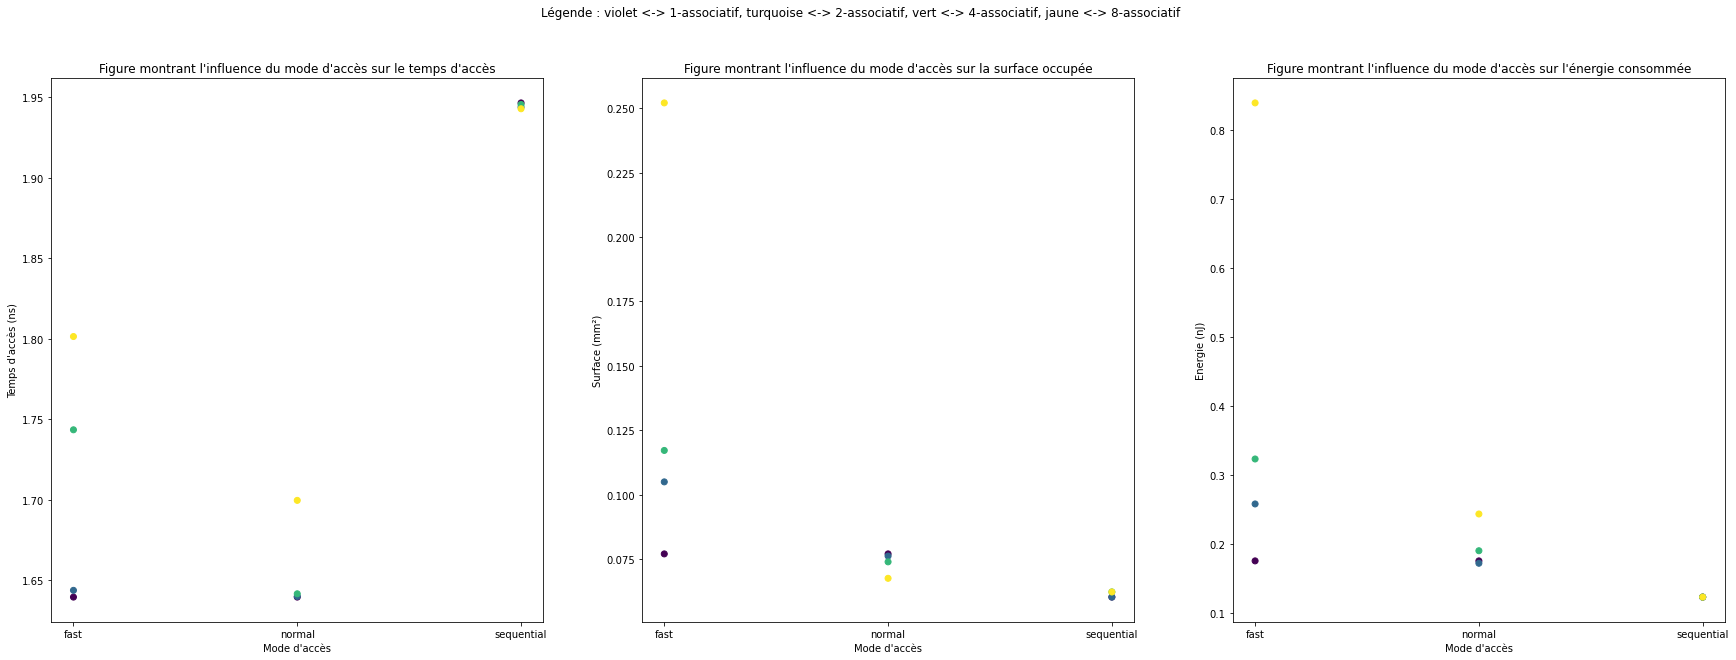

In [15]:
plt.figure(figsize=(30, 10))
plt.subplot(131)
plt.scatter(modes*len(associativity), ta3, c = [i//len(modes) for i in range(len(ta3))], cmap = 'viridis')
plt.xlabel("Mode d'accès")
plt.ylabel("Temps d'accès (ns)")
plt.title("Figure montrant l'influence du mode d'accès sur le temps d'accès")
plt.subplot(132)
plt.scatter(modes*len(associativity), surface3, c = [i//len(modes) for i in range(len(surface3))], cmap = 'viridis')
plt.xlabel("Mode d'accès")
plt.ylabel("Surface (mm²)")
plt.title("Figure montrant l'influence du mode d'accès sur la surface occupée")
plt.subplot(133)
plt.scatter(modes*len(associativity), energie3, c = [i//len(modes) for i in range(len(energie3))], cmap = 'viridis')
plt.xlabel("Mode d'accès")
plt.ylabel("Energie (nJ)")
plt.title("Figure montrant l'influence du mode d'accès sur l'énergie consommée")
plt.suptitle("Légende : violet <-> 1-associatif, turquoise <-> 2-associatif, vert <-> 4-associatif, jaune <-> 8-associatif")

<strong>Interprétation :</strong>

On remarque que, à mode d'accès fixé, le temps d'accès, l'énergie et la surface sont fonctions croissantes de l'associativité. Ainsi, en moyenne sur les différentes associativités, le mode d'accès :
<ul>
    <li>"normal" fournit un faible temps d'accès, une surface occupée relativement petite et une énergie consommée moyenne ;</li>
    <li>"fast" fournit un plus faible temps d'accès aux petites associativités que le mode "normal" qui augmente cependant plus rapidement avec l'associativité ainsi qu'une surface occupée et une énergie consommmée plus élevée que le mode "normal" qui augmentent fortement avec l'associativité ;</li>
    <li>"sequential" fournit un temps d'accès bien plus élevé que les autres modes, mais une plus petite surface occupée et une plus faible énergie consommée.</li>
</ul>

<strong>N.B. :</strong> On remarque aussi que, contrairement aux autres modes d'accès, la surface occupée nécessaire pour le mode d'accès "normal" est fonction décroissante de l'associativité.

### 4. Temps d'accès moyen TAMM

Pour la suite de ce TP, nous avons décidé de nous baser sur le processeur <a href="https://developer.arm.com/Processors/Cortex-A55">ARM 
Cortex-A55</a>. D’après la documentation technique, le processeur Cortex-A55 possède un 
cache L1 Instruction/Data de taille allant de 8 à 64 kB, un cache L2 de taille allant de 64 à 
256 kB et enfin un cache L3 optionnel de taille allant de 256 kB à 4 MB. Ainsi, nous allons 
utiliser ces différents paramètres pour la suite du TP.

On choisit un temps d'accès mémoire pour la SDRAM DDR5 32Gb placée dans le processeurs ARM Cortex-A55 de <a href="https://www.crucial.com/articles/about-memory/difference-between-speed-and-latency?fbclid=IwAR1MhUoyENs-YWAWMmWRVtkWrGjgUlwsVX2tvtcD9-AiBeR6bwIwI1sReA4">16,67 ns</a>.

L’objectif de ce TP est de trouver la 
configuration optimale afin d’avoir un <strong>temps d’accès moyen à la mémoire (TAMM) inférieur 2 
ns</strong> (et non 3 ns car TAMM toujours strictement inférieur à 3 ns pour ce processeur même dans la pire des configurations) ainsi qu’une <strong>consommation énergétique et une surface de cache minimales</strong>, tout en ayant des <strong>caches avec la plus grande capacité de stockage possible</strong>.

In [16]:
#Variables processeur ARM Cortex A55
L1_A55 = [8192, 16384, 32768, 65536]  # Ensemble des tailles de caches L1 possibles
L2_A55 = [65536, 131072, 262144]  # Ensemble des tailles de caches L2 possibles
L3_A55 = [524288, 1048576, 2097152, 4194304]  # Ensemble des tailles de caches L3 possibles
tauerr_A55 = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09]  # Ensemble des taux d'erreur possible pour les différents caches
tm_DDR5 = 16.67  # Temps d'accès mémoire RAM

<strong>Induction des résultats précédents :</strong>

<ol>
    <li>On choisit une faible associativité pour les caches de petites tailles (L1 data et instruction) pour ne pas trop augmenter le temps d'accès ;</li>
    <li>Si l'on ne se préoccupe pas d'une augmentation du temps d'accès, on privilégiera une taille de cache de 2 MB quand cela est possible (L2 et L3) pour diminuer l'énergie consommée par les caches, en faisant attention d'éviter de le combiner avec une associativité de 4 pour éviter une brusque augmentation de la surface occupée ;</li>
    <li>On évitera la taille de cache de 1 MB quand cela est possible (L2 et L3) qui consomme autant d'énergie que la taille de cache 4 MB et plus que celle 2 MB ;</li>
    <li>On évitera la parallélisation de la lecture et de l'écriture sur les caches basée sur plusieurs ports (elle n'apporte aucun avantage) et on privilégiera 1 port lecture/écriture qui consomme moins d'énergie et occupe une plus petite surface que 1 port lecture avec 1 port écriture ;</li>
    <li>Si l'on veut gagner en temps d'accès sans se préoccuper de l'énergie consommée et et de la surface occupée, on peut passer en mode d'accès "fast" uniquement pour les caches 1-associtatif ;</li>
    <li>Si l'on veut gagner en temps d'accès, on peut passer en mode d'accès "normal" pour les caches de grandes associativités (2, 4 ou 8) ;</li>
    <li>En mode d'accès "normal", on peut augmenter l'associativité pour diminuer la surface occupée ;</li>
    <li> Si l'on veut diminuer l'énergie consommée et la surface occupée sans se préoccuper du temps d'accès, on peut passer en mode d'accès "sequential" quelle que soit l'associativité.</li>
</ol>

#### Première expérience 

In [17]:
# On vise les tailles de cache maximale avec le temps d'accès le plus petit en faisant varier les autres paramètres
simu1 = []

# Tuples des paramètres de chaque cache dans le même ordre (taille, associativité, mode d'accès, ports read/write, read, et write)
L1d = (65536, 1, 'fast', 1, 0, 0)  # Petite associativité et "fast"
L1i = (65536, 1, 'fast', 1, 0, 0)  # idem
L2 = (131072, 8, 'normal', 1, 0, 0)  # Eviter 2MB qui augmente TAMM, 1MB augmente énergie => 'normal', 8-associatif => - de surface
L3 = (4194304, 8, 'normal', 1, 0, 0)  # même raisonnement que précédent

# Simulations des différents caches
print(f"Simulation cache L1 data {L1d[1]}-associatif accessible en mode {L1d[2]}...")
write_cfg(*L1d)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu1.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L1 instruction {L1i[1]}-associatif accessible en mode {L1i[2]}...")
write_cfg(*L1i)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu1.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L2 {L2[1]}-associatif accessible en mode {L2[2]}...")
write_cfg(*L2)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu1.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L3 {L3[1]}-associatif accessible en mode {L3[2]}...")
write_cfg(*L3)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu1.append([t, float(x[0]) * float(x[1]), e])

Simulation cache L1 data 1-associatif accessible en mode fast...
Simulation cache L1 instruction 1-associatif accessible en mode fast...
Simulation cache L2 8-associatif accessible en mode normal...
Simulation cache L3 8-associatif accessible en mode normal...


In [18]:
etot1 = getConsumedEnergy(np.array(simu1)[:, 2])
stot1 = getSurface(np.array(simu1)[:, 1])

print("Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 :")
print(f"\t- une énergie totale consommée de {etot1} nJ.")
print(f"\t- une surface totale occupée de {stot1} mm².")

Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 :
	- une énergie totale consommée de 2.83663941 nJ.
	- une surface totale occupée de 3.230386020787 mm².


Text(0.5, 1.0, "Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

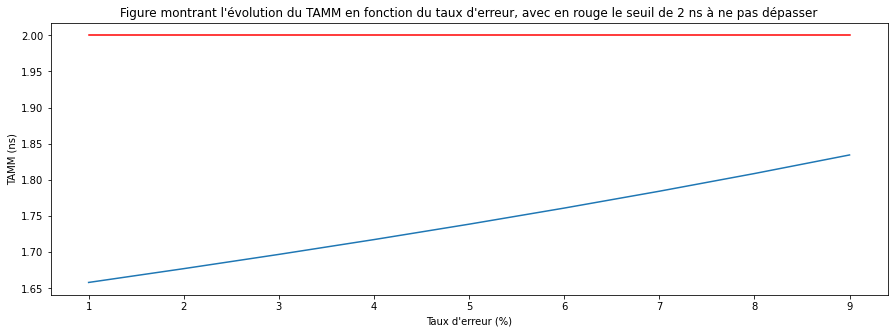

In [19]:
absc = [x*100 for x in tauerr_A55]
ordo = []

ta = np.array(simu1)[1:, 0]  # Caches L1d et L1i identiques
for taue in tauerr_A55:
    ordo.append(getTAMM(ta, taue, tm_DDR5))

plt.figure(figsize=(15,5))
plt.plot(absc, ordo)
plt.plot(absc, [2 for x in absc], 'r')  # Seuil de 3ns du TAMM à ne pas dépasser
plt.xlabel("Taux d'erreur (%)")
plt.ylabel("TAMM (ns)")
plt.title("Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

<strong>Conclusion partielle :</strong>

Etant très éloigné du TAMM maximum acceptable d'après le cahier des charges, nous pouvons encore l'augmenter tout en diminuant la surface totale occupée et l'énergie consommée en jouant sur d'autres paramètres.

#### Deuxième expérience 

In [20]:
# On vise les tailles de cache maximale avec le temps d'accès le plus petit en faisant varier les autres paramètres
simu2 = []

# Tuples des paramètres de chaque cache dans le même ordre (taille, associativité, mode d'accès, ports read/write, read, et write)
L1d = (65536, 1, 'fast', 1, 0, 0)
L1i = (65536, 1, 'fast', 1, 0, 0)
L2 = (131072, 8, 'sequential', 1, 0, 0)  # Mode d'accès séquentiel pour diminuer l'énergie consommée
L3 = (4194304, 8, 'sequential', 1, 0, 0)  # Idem

# Simulations des différents caches
print(f"Simulation cache L1 data {L1d[1]}-associatif accessible en mode {L1d[2]}...")
write_cfg(*L1d)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu2.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L1 instruction {L1i[1]}-associatif accessible en mode {L1i[2]}...")
write_cfg(*L1i)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu2.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L2 {L2[1]}-associatif accessible en mode {L2[2]}...")
write_cfg(*L2)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu2.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L3 {L3[1]}-associatif accessible en mode {L3[2]}...")
write_cfg(*L3)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu2.append([t, float(x[0]) * float(x[1]), e])

Simulation cache L1 data 1-associatif accessible en mode fast...
Simulation cache L1 instruction 1-associatif accessible en mode fast...
Simulation cache L2 8-associatif accessible en mode sequential...
Simulation cache L3 8-associatif accessible en mode sequential...


In [21]:
etot2 = getConsumedEnergy(np.array(simu2)[:, 2])
stot2 = getSurface(np.array(simu2)[:, 1])

print("Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :")
print(f"\t- énergie totale consommée de {etot2} nJ, soit une diminution de {np.round(etot1-etot2, 3)} nJ par rapport à la simulation 1.")
print(f"\t- surface totale occupée de {stot2} mm², soit une diminution de {np.round(stot1-stot2, 6)} mm² par rapport à la simulation 1.")

Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :
	- énergie totale consommée de 2.80165295 nJ, soit une diminution de 0.035 nJ par rapport à la simulation 1.
	- surface totale occupée de 3.2388092122199996 mm², soit une diminution de -0.008423 mm² par rapport à la simulation 1.


Text(0.5, 1.0, "Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

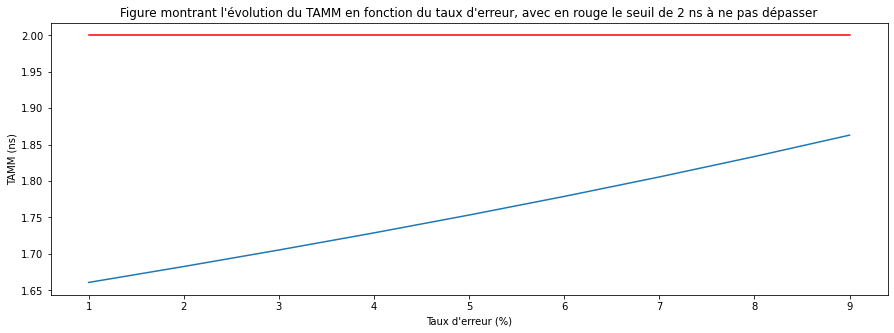

In [22]:
absc = [x*100 for x in tauerr_A55]
ordo = []

ta = np.array(simu2)[1:, 0]  # Caches L1d et L1i identiques
for taue in tauerr_A55:
    ordo.append(getTAMM(ta, taue, tm_DDR5))

plt.figure(figsize=(15,5))
plt.plot(absc, ordo)
plt.plot(absc, [2 for x in absc], 'r')  # Seuil de 3ns du TAMM à ne pas dépasser
plt.xlabel("Taux d'erreur (%)")
plt.ylabel("TAMM (ns)")
plt.title("Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

<strong>Conclusion partielle :</strong>

En changeant le mode d'accès des caches L2 et L3 pour "sequential", nous avons gagné comme prévu sur le plan énergétique, mais perdu sur le plan de la surface occupée car ces caches sont de grande associativités (cf. schéma surface en fonction du mode d'accès). De plus, on ne s'est pas significativement rapproché du TAMM maximum.

#### Troisième expérience 

In [23]:
# On vise les tailles de cache maximale avec le temps d'accès le plus petit en faisant varier les autres paramètres
simu3 = []

# Tuples des paramètres de chaque cache dans le même ordre (taille, associativité, mode d'accès, ports read/write, read, et write)
L1d = (32768, 1, 'fast', 1, 0, 0)
L1i = (32768, 1, 'fast', 1, 0, 0)
L2 = (131072, 4, 'sequential', 1, 0, 0)
L3 = (4194304, 4, 'sequential', 1, 0, 0)

# Simulations des différents caches
print(f"Simulation cache L1 data {L1d[1]}-associatif accessible en mode {L1d[2]}...")
write_cfg(*L1d)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu3.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L1 instruction {L1i[1]}-associatif accessible en mode {L1i[2]}...")
write_cfg(*L1i)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu3.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L2 {L2[1]}-associatif accessible en mode {L2[2]}...")
write_cfg(*L2)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu3.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L3 {L3[1]}-associatif accessible en mode {L3[2]}...")
write_cfg(*L3)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu3.append([t, float(x[0]) * float(x[1]), e])

Simulation cache L1 data 1-associatif accessible en mode fast...
Simulation cache L1 instruction 1-associatif accessible en mode fast...
Simulation cache L2 4-associatif accessible en mode sequential...
Simulation cache L3 4-associatif accessible en mode sequential...


In [24]:
etot3 = getConsumedEnergy(np.array(simu3)[:, 2])
stot3 = getSurface(np.array(simu3)[:, 1])

print("Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :")
print(f"\t- énergie totale consommée de {etot3} nJ, soit une diminution de {np.round(etot2-etot3, 3)} nJ par rapport à la simulation 2.")
print(f"\t- surface totale occupée de {stot3} mm², soit une diminution de {np.round(stot1-stot3, 6)} mm² par rapport à la simulation 1.")

Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :
	- énergie totale consommée de 2.74403879 nJ, soit une diminution de 0.058 nJ par rapport à la simulation 2.
	- surface totale occupée de 3.1713665924880003 mm², soit une diminution de 0.059019 mm² par rapport à la simulation 1.


Text(0.5, 1.0, "Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

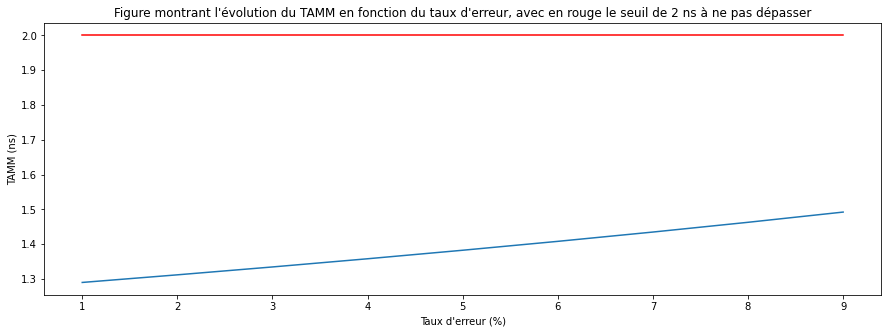

In [25]:
absc = [x*100 for x in tauerr_A55]
ordo = []

ta = np.array(simu3)[1:, 0]  # Caches L1d et L1i identiques
for taue in tauerr_A55:
    ordo.append(getTAMM(ta, taue, tm_DDR5))

plt.figure(figsize=(15,5))
plt.plot(absc, ordo)
plt.plot(absc, [2 for x in absc], 'r')  # Seuil de 3ns du TAMM à ne pas dépasser
plt.xlabel("Taux d'erreur (%)")
plt.ylabel("TAMM (ns)")
plt.title("Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

<strong>Conclusion partielle :</strong>

En changeant l'associativité des caches L2 et L3 pour 4 au lieu de 8, on diminue fortement l'ensemble des critères d'évaluation de notre processeur (TAMM, énergie consommée et surface occupée).

#### Quatrième expérience 

In [26]:
# On vise les tailles de cache maximale avec le temps d'accès le plus petit en faisant varier les autres paramètres
simu4 = []

# Tuples des paramètres de chaque cache dans le même ordre (taille, associativité, mode d'accès, ports read/write, read, et write)
L1d = (32768, 1, 'fast', 1, 0, 0)
L1i = (32768, 1, 'fast', 1, 0, 0)
L2 = (65536, 4, 'sequential', 1, 0, 0)
L3 = (4194304, 4, 'sequential', 1, 0, 0)

# Simulations des différents caches
print(f"Simulation cache L1 data {L1d[1]}-associatif accessible en mode {L1d[2]}...")
write_cfg(*L1d)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu4.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L1 instruction {L1i[1]}-associatif accessible en mode {L1i[2]}...")
write_cfg(*L1i)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu4.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L2 {L2[1]}-associatif accessible en mode {L2[2]}...")
write_cfg(*L2)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu4.append([t, float(x[0]) * float(x[1]), e])

print(f"Simulation cache L3 {L3[1]}-associatif accessible en mode {L3[2]}...")
write_cfg(*L3)
t, cs, e = get_info()
x = re.findall("\d+\.\d+",cs)
simu4.append([t, float(x[0]) * float(x[1]), e])

Simulation cache L1 data 1-associatif accessible en mode fast...
Simulation cache L1 instruction 1-associatif accessible en mode fast...
Simulation cache L2 4-associatif accessible en mode sequential...
Simulation cache L3 4-associatif accessible en mode sequential...


In [27]:
etot4 = getConsumedEnergy(np.array(simu4)[:, 2])
stot4 = getSurface(np.array(simu4)[:, 1])

print("Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :")
print(f"\t- énergie totale consommée de {etot4} nJ, soit une diminution de {np.round(etot3-etot4, 3)} nJ par rapport à la simulation 3.")
print(f"\t- surface totale occupée de {stot4} mm², soit une diminution de {np.round(stot3-stot4, 6)} mm² par rapport à la simulation 3.")

Avec les paramètres choisis ci-dessus, on obtient pour le processeur ARM Cortex-A55 une :
	- énergie totale consommée de 2.6334713499999998 nJ, soit une diminution de 0.111 nJ par rapport à la simulation 3.
	- surface totale occupée de 3.100083182889 mm², soit une diminution de 0.071283 mm² par rapport à la simulation 3.


Text(0.5, 1.0, "Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

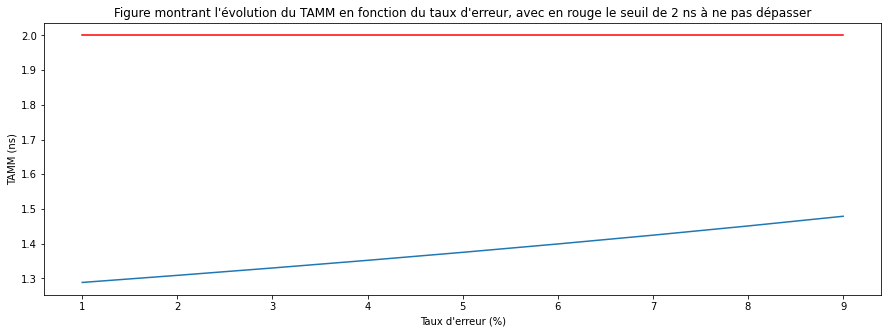

In [28]:
absc = [x*100 for x in tauerr_A55]
ordo = []

ta = np.array(simu4)[1:, 0]  # Caches L1d et L1i identiques
for taue in tauerr_A55:
    ordo.append(getTAMM(ta, taue, tm_DDR5))

plt.figure(figsize=(15,5))
plt.plot(absc, ordo)
plt.plot(absc, [2 for x in absc], 'r')  # Seuil de 3ns du TAMM à ne pas dépasser
plt.xlabel("Taux d'erreur (%)")
plt.ylabel("TAMM (ns)")
plt.title("Figure montrant l'évolution du TAMM en fonction du taux d'erreur, avec en rouge le seuil de 2 ns à ne pas dépasser")

<strong>Conclusion partielle :</strong>

En changeant la taille du cache L2 pour 64kB au lieu de 1MB, on diminue évidemment la surface occupée par le processeur mais aussi fortement l'énergie consommée par ce cache (cf. graphique énergie consommée en fonction de la taille du cache), sans toucher au TAMM.

Ainsi, en choisissant un processeur ARM Cortex-A55 possédant deux caches L1 (data et instruction) non associatif de 32kB en mode "fast", un cache L2 4-associatif de 64 kB en mode "sequential" et un cache L3 4-associatif de 4 MB en mode "sequential", on trouve une configuration relativement optimale qui :
<ul>
    <li>respecte le critère sur le TAMM (> 2 ns)</li>
    <li>minimise l'énergie consommée par le processeur (relativement aux configurations testées et à l'évolution attendue de l'énergie d'après les questions précédentes)</li>
    <li>minimise la surface occupée par le processeur (relativement aux configurations testées et à l'évolution attendue de la surface d'après les questions précédentes)</li>
</ul>